In [1]:
import numpy as np
from itertools import product
from scipy.linalg import expm

def unitary_to_ptm(unitary: np.ndarray) -> np.ndarray:
    """
    Converts a unitary matrix to its corresponding Pauli Transfer Matrix (PTM).
    Assumes the input is a 2-qubit unitary (i.e., 4x4 matrix).
    
    Args:
        unitary (np.ndarray): A 4x4 unitary matrix.

    Returns:
        np.ndarray: A 16x16 Pauli Transfer Matrix (PTM).
    """
    # Check input
    dim = unitary.shape[0]
    assert unitary.shape == (dim, dim), "Unitary must be square."
    assert np.allclose(unitary @ unitary.conj().T, np.eye(dim)), "Input must be unitary."
    assert dim == 4, "Function currently supports only 2-qubit (4x4) unitaries."

    # Define single-qubit Pauli matrices
    I = np.eye(2, dtype=complex)
    X = np.array([[0, 1], [1, 0]], dtype=complex)
    Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
    Z = np.array([[1, 0], [0, -1]], dtype=complex)
    paulis = [I, X, Y, Z]

    # Build 2-qubit Pauli basis: tensor products
    basis = [np.kron(p1, p2) for p1, p2 in product(paulis, repeat=2)]
    basis = np.array(basis)  # shape (16, 4, 4)

    # Compute PTM: PTM[i,j] = (1/dim) * Tr[Pi† U Pj U†]
    ptm = np.zeros((16, 16), dtype=complex)
    for i, Pi in enumerate(basis):
        for j, Pj in enumerate(basis):
            transformed = unitary @ Pj @ unitary.conj().T
            ptm[j, i] = np.trace(Pi.conj().T @ transformed) / dim

    # Ensure result is real
    assert np.abs(ptm.imag).max() < 1e-10, "PTM has significant imaginary parts."
    return ptm.real


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
import matplotlib.patches as mpatches
import matplotlib
from fractions import Fraction
from itertools import product

# --- Filename helper ---
def filename_label(phi):
    frac = Fraction(phi / np.pi).limit_denominator(8)
    num, den = frac.numerator, frac.denominator
    if num == 0:
        return "0"
    if den == 1:
        return "pi" if num == 1 else f"{num}pi"
    if num == 1:
        return f"pi_over_{den}"
    return f"{num}pi_over_{den}"

# --- Unitaries ---
X = np.array([[0, 1], [1, 0]])
Y = np.array([[0, -1j], [1j, 0]])
Z = np.array([[1, 0], [0, -1]])
I = np.eye(2)
H = (1 / np.sqrt(2)) * np.array([[1, 1], [1, -1]])
S = np.array([[1, 0], [0, 1j]])
S_dagger = S.conj().T

def zz_unitary(phi):
    return np.diag([
        np.exp(-1j * phi / 2),
        np.exp(1j * phi / 2),
        np.exp(1j * phi / 2),
        np.exp(-1j * phi / 2),
    ])

def dme_heisenberg(phi):
    ZZ_phi = zz_unitary(phi)
    YY_phi = (
        np.kron(S_dagger, I) @ np.kron(H, I) @
        np.kron(I, S_dagger) @ np.kron(I, H) @
        zz_unitary(phi) @
        np.kron(H, I) @ np.kron(S, I) @
        np.kron(I, H) @ np.kron(I, S)
    )
    XX_phi = (
        np.kron(H, I) @ np.kron(I, H) @
        zz_unitary(phi) @
        np.kron(H, I) @ np.kron(I, H)
    )
    return ZZ_phi @ YY_phi @ XX_phi

# --- PTM labels ---
pauli_labels_1q = ['I', 'X', 'Y', 'Z']
ptm_labels = [a + b for a, b in product(pauli_labels_1q, repeat=2)]

# --- Plotting helper ---
def plot_process_matrix_colormap(m: np.ndarray, basis_labels, ax=None, title=None, cmap='RdBu_r'):
    nx, ny = m.shape
    if ax is None:
        fig, ax = plt.subplots()
    ax.axis("scaled")
    ax.patch.set_facecolor("white")
    mflat = m.flatten()
    vals = np.real(mflat)
    mags = np.abs(mflat) ** 0.5
    norm = Normalize(vmin=-1, vmax=1)
    colors = plt.get_cmap(cmap)(norm(vals))
    idx = 0
    for ix in range(nx):
        for iy in range(ny):
            ax.add_artist(
                mpatches.RegularPolygon(
                    xy=(ix, iy),
                    numVertices=4,
                    orientation=np.pi / 4,
                    color=colors[idx],
                    radius=2.0 ** -0.5 * mags[idx],
                    linewidth=0.0,
                )
            )
            idx += 1
    ax.set_xticks(np.arange(nx))
    ax.set_xticklabels(basis_labels, rotation=90)
    ax.set_yticks(np.arange(ny))
    ax.set_yticklabels(basis_labels)
    ax.set_xlim(-0.5, nx - 0.5)
    ax.set_ylim(-0.5, ny - 0.5)
    ax.grid(False)
    if title:
        ax.set_title(title)

def RZ(phi):
    return expm(-1j * phi * Z)

def RX(theta):
    return expm(-1j * theta * X)

def RY(theta):
    return expm(-1j * theta * Y)

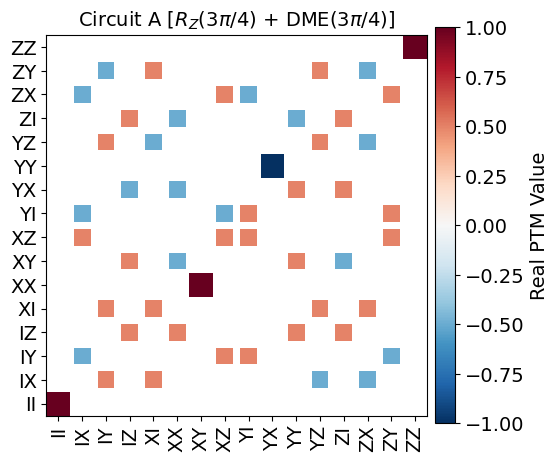

Saved ideal DME PTM plot for θ=2.356 to Ideal_DME_phi_3pi_over_4_ptm.png


In [3]:
# --- Plot ideal PTMs ---
phi_list = [3*np.pi/4]

for phi_target in phi_list:
    ptm_ideal = unitary_to_ptm(dme_heisenberg(phi_target)@ np.kron(I, RZ(phi_target)))

    matplotlib.rcParams.update({
        "text.usetex": False,
        "font.size": 14,
        "axes.titlesize": 14,
        "axes.labelsize": 14,
        "xtick.labelsize": 14,
        "ytick.labelsize": 14,
        "legend.fontsize": 14,
        "figure.titlesize": 14,
    })

    fig, ax = plt.subplots(1, 1, figsize=(5, 5))
    plot_process_matrix_colormap(
        ptm_ideal,
        ptm_labels,
        ax=ax,
        title=r"Circuit A [$R_Z(3\pi/4)$ + DME($3\pi/4$)]",
    )

    plt.tight_layout()
    sm = ScalarMappable(norm=Normalize(vmin=-1, vmax=1), cmap='RdBu_r')
    sm.set_array([])
    cbar = fig.colorbar(
        sm,
        ax=ax,
        location='right',
        fraction=0.08,
        pad=0.02,
    )
    cbar.set_label("Real PTM Value", fontsize=14)
    cbar.ax.tick_params(labelsize=14)

    fname_label = filename_label(phi_target)
    fname = f"Ideal_DME_phi_{fname_label}_ptm.png"
    plt.savefig(fname, dpi=600, bbox_inches='tight')
    plt.show()
    print(f"Saved ideal DME PTM plot for θ={phi_target:.3f} to {fname}")


In [4]:
def ptrace(matrix, index=1, n1=2, n2=2):
    """Partial trace over one subsystem."""
    current_tensor = matrix.reshape([n1, n2, n1, n2])
    if index == 1:
        return np.trace(current_tensor, axis1=1, axis2=3)
    elif index == 2:
        return np.trace(current_tensor, axis1=0, axis2=2)
    else:
        print('Error')

In [5]:
psi0 = np.array([[1, 0], [0, 0]])

In [119]:
import numpy as np

def shift_y_by_delta(theta_list, y_val, delta):
    """
    Shift y_val to correspond to theta_list + delta (mod π),
    preserving original values without interpolation.

    Parameters:
    - theta_list: np.ndarray, original theta values (non-uniform)
    - y_val: np.ndarray, corresponding y values
    - delta: float, shift value in radians

    Returns:
    - shifted_y_val: np.ndarray, y values permuted to match theta + delta wrapped into [-π/2, π/2]
    """
    period = np.pi

    # Shift and wrap theta
    new_theta = theta_list + delta
    new_theta_wrapped = ((new_theta + np.pi/2) % period) - np.pi/2

    # Sort new_theta_wrapped and reorder y_val accordingly
    sort_idx = np.argsort(new_theta_wrapped)
    shifted_y_val = y_val[sort_idx]

    return shifted_y_val


Text(0, 0.5, 'Energy $E_1$')

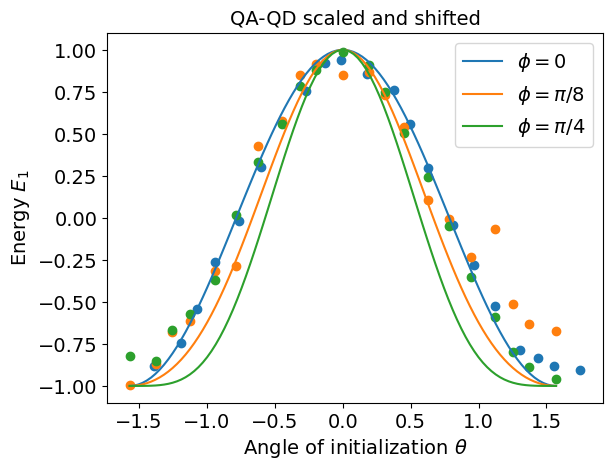

In [142]:
import numpy as np
import matplotlib.pyplot as plt

# Define your parameters and functions (assuming they are already defined)
theta_list = np.linspace(-np.pi/2, np.pi/2, 100)
# phi_list = [0, np.pi/8, np.pi/4, 3*np.pi/4, 7*np.pi/8]
# phi_name = [r"$0$", r"$\pi/8$", r"$\pi/4$", r"$\pi/2$", r"$\pi$"]

phi_list = [0, np.pi/8, np.pi/4]
phi_name = [r"$0$", r"$\pi/8$", r"$\pi/4$"]
# Loop over each phi value and compute the necessary quantities
for idx, phi in enumerate(phi_list):
    # Precompute the unitary matrix
    unitary_list = [dme_heisenberg(phi) @ np.kron(I, RZ(phi)) @ np.kron(RX(theta), RX(theta)) for theta in theta_list]
    
    # Compute final matrices for the system
    final_matrices = [unitary @ np.kron(psi0, psi0) @ unitary.conj().T for unitary in unitary_list]
    
    # Compute the subsystems and the energies
    subsystem_1, subsystem_2 = [ptrace(matrix, 1) for matrix in final_matrices], [ptrace(matrix, 2) for matrix in final_matrices]
    original_system = [RX(theta) @ psi0 @ RX(-theta) for theta in theta_list]
    
    # Compute energy values
    energy_init = [system[0][0] - system[1][1] for system in original_system]
    energy_1 = [system[0][0] - system[1][1] for system in subsystem_1]
    
    # Plot the difference between initial energy and energy after subsystem interaction
    plt.plot(theta_list, np.array(energy_1), label=r'$\phi =$' + phi_name[idx])

plt.scatter(theta_X/2+0.18,E1_meas_Z0)
plt.scatter(theta_X/2,shift_y_by_delta(theta_X/2,E1_meas_Z8*4.3+0.1,-0.5))
plt.scatter(theta_X/2,shift_y_by_delta(theta_X/2,E1_meas_Z4*2.3,-0.1))


# Show the legend and plot
plt.legend()
plt.xlabel(r'Angle of initialization $\theta$')
plt.title('QA-QD scaled and shifted')
# plt.ylabel(r'Energy reduction $\Delta E = E_{DBAC} - E_{init}$')
plt.ylabel(r'Energy $E_1$')
# plt.ylim([-1.1,1.1])

(-1.1, 1.1)

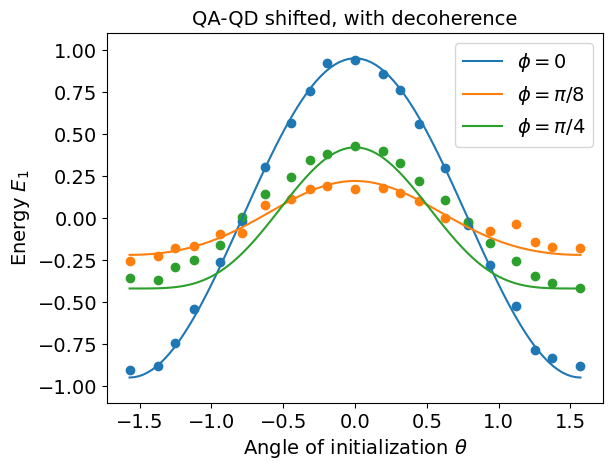

In [164]:
import numpy as np
import matplotlib.pyplot as plt

# Define your parameters and functions (assuming they are already defined)
theta_list = np.linspace(-np.pi/2, np.pi/2, 100)
# phi_list = [0, np.pi/8, np.pi/4, 3*np.pi/4, 7*np.pi/8]
# phi_name = [r"$0$", r"$\pi/8$", r"$\pi/4$", r"$\pi/2$", r"$\pi$"]

phi_list = [0, np.pi/8, np.pi/4]
phi_name = [r"$0$", r"$\pi/8$", r"$\pi/4$"]
# Loop over each phi value and compute the necessary quantities
for idx, phi in enumerate(phi_list):
    # Precompute the unitary matrix
    unitary_list = [dme_heisenberg(phi) @ np.kron(I, RZ(phi)) @ np.kron(RX(theta), RX(theta)) for theta in theta_list]
    
    # Compute final matrices for the system
    final_matrices = [unitary @ np.kron(psi0, psi0) @ unitary.conj().T for unitary in unitary_list]
    
    if idx==0:
        final_matrices = [apply_depolarizing_noise(matrix,0.05) for matrix in final_matrices]
    elif idx==1:
        final_matrices = [apply_depolarizing_noise(matrix,0.78) for matrix in final_matrices]
    elif idx==2:
        final_matrices = [apply_depolarizing_noise(matrix,0.58) for matrix in final_matrices]

    # Compute the subsystems and the energies
    subsystem_1, subsystem_2 = [ptrace(matrix, 1) for matrix in final_matrices], [ptrace(matrix, 2) for matrix in final_matrices]
    original_system = [RX(theta) @ psi0 @ RX(-theta) for theta in theta_list]

    # Compute energy values
    energy_init = [system[0][0] - system[1][1] for system in original_system]
    energy_1 = [system[0][0] - system[1][1] for system in subsystem_1]
    
    # Plot the difference between initial energy and energy after subsystem interaction
    plt.plot(theta_list, np.array(energy_1), label=r'$\phi =$' + phi_name[idx])

plt.scatter(theta_X/2,shift_y_by_delta(theta_X/2,E1_meas_Z0,0.18))
plt.scatter(theta_X/2,shift_y_by_delta(theta_X/2,E1_meas_Z8,-0.5))
plt.scatter(theta_X/2,shift_y_by_delta(theta_X/2,E1_meas_Z4,-0.1))


# Show the legend and plot
plt.legend()
plt.xlabel(r'Angle of initialization $\theta$')
plt.title('QA-QD shifted, with decoherence')
# plt.ylabel(r'Energy reduction $\Delta E = E_{DBAC} - E_{init}$')
plt.ylabel(r'Energy $E_1$')
plt.ylim([-1.1,1.1])

(-1.1, 1.1)

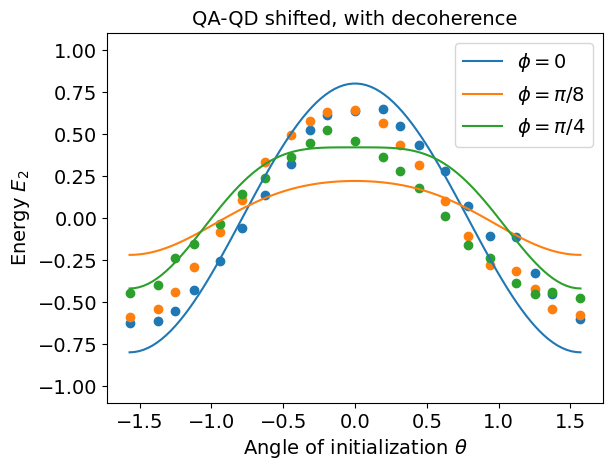

In [172]:
import numpy as np
import matplotlib.pyplot as plt

# Define your parameters and functions (assuming they are already defined)
theta_list = np.linspace(-np.pi/2, np.pi/2, 100)
# phi_list = [0, np.pi/8, np.pi/4, 3*np.pi/4, 7*np.pi/8]
# phi_name = [r"$0$", r"$\pi/8$", r"$\pi/4$", r"$\pi/2$", r"$\pi$"]

phi_list = [0, np.pi/8, np.pi/4]
phi_name = [r"$0$", r"$\pi/8$", r"$\pi/4$"]
# Loop over each phi value and compute the necessary quantities
for idx, phi in enumerate(phi_list):
    # Precompute the unitary matrix
    unitary_list = [dme_heisenberg(phi) @ np.kron(I, RZ(phi)) @ np.kron(RX(theta), RX(theta)) for theta in theta_list]
    
    # Compute final matrices for the system
    final_matrices = [unitary @ np.kron(psi0, psi0) @ unitary.conj().T for unitary in unitary_list]
    
    if idx==0:
        final_matrices = [apply_depolarizing_noise(matrix,0.20) for matrix in final_matrices]
    elif idx==1:
        final_matrices = [apply_depolarizing_noise(matrix,0.78) for matrix in final_matrices]
    elif idx==2:
        final_matrices = [apply_depolarizing_noise(matrix,0.58) for matrix in final_matrices]

    # Compute the subsystems and the energies
    subsystem_1, subsystem_2 = [ptrace(matrix, 1) for matrix in final_matrices], [ptrace(matrix, 2) for matrix in final_matrices]
    original_system = [RX(theta) @ psi0 @ RX(-theta) for theta in theta_list]

    # Compute energy values
    energy_init = [system[0][0] - system[1][1] for system in original_system]
    energy_2 = [system[0][0] - system[1][1] for system in subsystem_2]
    
    # Plot the difference between initial energy and energy after subsystem interaction
    plt.plot(theta_list, np.array(energy_2), label=r'$\phi =$' + phi_name[idx])

plt.scatter(theta_X/2,shift_y_by_delta(theta_X/2,E2_meas_Z0,0.18-np.pi/4))
plt.scatter(theta_X/2,shift_y_by_delta(theta_X/2,E2_meas_Z8,-0.5))
plt.scatter(theta_X/2,shift_y_by_delta(theta_X/2,E2_meas_Z4,-0.1))


# Show the legend and plot
plt.legend()
plt.xlabel(r'Angle of initialization $\theta$')
plt.title('QA-QD shifted, with decoherence')
# plt.ylabel(r'Energy reduction $\Delta E = E_{DBAC} - E_{init}$')
plt.ylabel(r'Energy $E_2$')
plt.ylim([-1.1,1.1])

Text(0, 0.5, 'Total Energy')

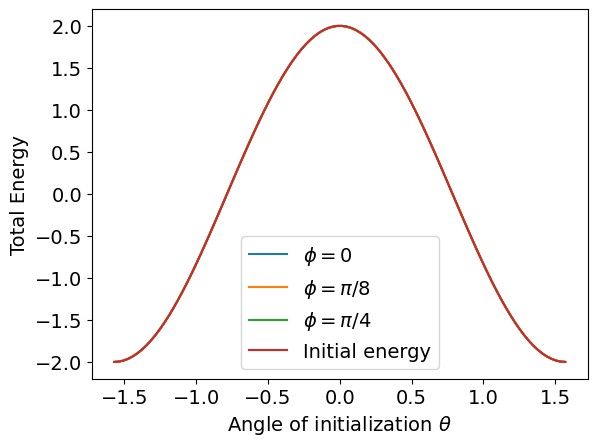

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Define your parameters and functions (assuming they are already defined)
theta_list = np.linspace(-np.pi/2, np.pi/2, 100)
# phi_list = [0, np.pi/8, np.pi/4, 3*np.pi/4, 7*np.pi/8]
# phi_name = [r"$0$", r"$\pi/8$", r"$\pi/4$", r"$\pi/2$", r"$\pi$"]

phi_list = [0, np.pi/8, np.pi/4]
phi_name = [r"$0$", r"$\pi/8$", r"$\pi/4$"]
# Loop over each phi value and compute the necessary quantities
for idx, phi in enumerate(phi_list):
    # Precompute the unitary matrix
    unitary_list = [dme_heisenberg(phi) @ np.kron(I, RZ(phi)) @ np.kron(RX(theta), RX(theta)) for theta in theta_list]
    
    # Compute final matrices for the system
    final_matrices = [unitary @ np.kron(psi0, psi0) @ unitary.conj().T for unitary in unitary_list]
    
    # Compute the subsystems and the energies
    subsystem_1, subsystem_2 = [ptrace(matrix, 1) for matrix in final_matrices], [ptrace(matrix, 2) for matrix in final_matrices]
    original_system = [RX(theta) @ psi0 @ RX(-theta) for theta in theta_list]
    
    
    # Compute energy values
    energy_1 = [system[0][0] - system[1][1] for system in subsystem_1]
    energy_2 = [system[0][0] - system[1][1] for system in subsystem_2]
    energy_init = [system[0][0] - system[1][1] for system in original_system]

    # Plot the difference between initial energy and energy after subsystem interaction
    plt.plot(theta_list, np.array(energy_1) + np.array(energy_2), label=r'$\phi =$' + phi_name[idx])
plt.plot(theta_list, np.array(energy_init)*2, label = "Initial energy")

# plt.scatter(theta_X/2,E2_meas_Z0)
# plt.scatter(theta_X/2,E2_meas_Z8)
# plt.scatter(theta_X/2,E2_meas_Z4)


# Show the legend and plot
plt.legend()
plt.xlabel(r'Angle of initialization $\theta$')
# plt.ylabel(r'Energy reduction $\Delta E = E_{DBAC} - E_{init}$')
plt.ylabel(r'Total Energy')
# plt.ylim([-1.1,1.1])

In [59]:
import pandas as pd
import numpy as np

# Define numeric theta_X manually
theta_X = np.array([
    -np.pi/8, -np.pi/5, -2*np.pi/7, -2*np.pi/5, -np.pi/2,
    -3*np.pi/5, -5*np.pi/7, -4*np.pi/5, -7*np.pi/8, -np.pi,
    0,
    np.pi/8, np.pi/5, 2*np.pi/7, 2*np.pi/5, np.pi/2,
    3*np.pi/5, 5*np.pi/7, 4*np.pi/5, 7*np.pi/8, np.pi
])

# Get sort indices and sort theta_X
sorted_indices = np.argsort(theta_X)
theta_X = theta_X[sorted_indices]

# Define suffix
suffix = "Z0"
# Load data
df = pd.read_csv("energy_values_A_" + suffix + ".csv", sep=",")  # or sep="," if needed

# Extract and sort each energy column, assign to globals with suffix
for col in ['E1_ideal', 'E2_ideal', 'E1_meas', 'E2_meas']:
    globals()[f"{col}_{suffix}"] = df[col].to_numpy()[sorted_indices]
    print(f"{col}_{suffix}")

# Define suffix
suffix = "Z4"
# Load data
df = pd.read_csv("energy_values_A_" + suffix + ".csv", sep=",")  # or sep="," if needed

# Extract and sort each energy column, assign to globals with suffix
for col in ['E1_ideal', 'E2_ideal', 'E1_meas', 'E2_meas']:
    globals()[f"{col}_{suffix}"] = df[col].to_numpy()[sorted_indices]
    print(f"{col}_{suffix}")

# Define suffix
suffix = "Z8"
# Load data
df = pd.read_csv("energy_values_A_" + suffix + ".csv", sep=",")  # or sep="," if needed

# Extract and sort each energy column, assign to globals with suffix
for col in ['E1_ideal', 'E2_ideal', 'E1_meas', 'E2_meas']:
    globals()[f"{col}_{suffix}"] = df[col].to_numpy()[sorted_indices]
    print(f"{col}_{suffix}")

E1_ideal_Z0
E2_ideal_Z0
E1_meas_Z0
E2_meas_Z0
E1_ideal_Z4
E2_ideal_Z4
E1_meas_Z4
E2_meas_Z4
E1_ideal_Z8
E2_ideal_Z8
E1_meas_Z8
E2_meas_Z8


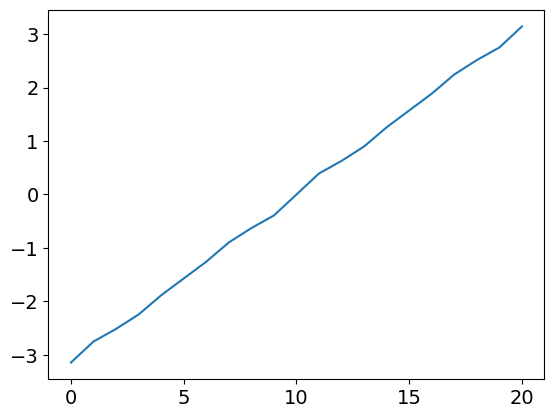

In [51]:
plt.plot(theta_X_sorted)

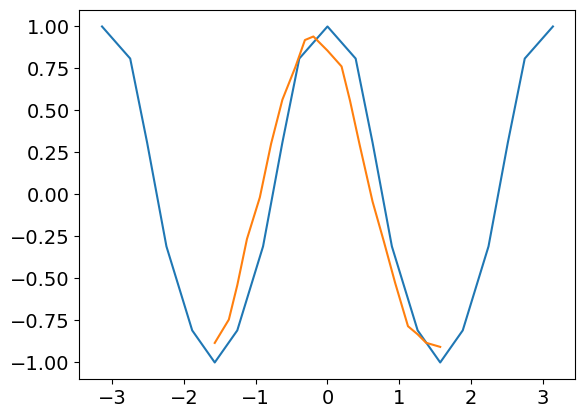

In [40]:
plt.plot(theta_X_sorted,E1_ideal_Z0_sorted)
plt.plot(theta_X_sorted/2,E1_meas_Z0_sorted)
# plt.plot(theta_X,E2_ideal)

In [145]:
# Add depolarizing noise to the density matrix
def apply_depolarizing_noise(rho, p=0.5):
    dim = rho.shape[0]
    identity = np.eye(dim)
    return (1 - p) * rho + (p / dim) * identity

def apply_bitflip_error(state, p=0.7):
    return 0.2*(RX(np.pi/2) @ state) + 0.8*state if np.random.rand() < p else state

def apply_dephasing_noise(rho, p=0.5):
    return (1 - p) * rho + p * Z@rho@Z  # Dephasing noise

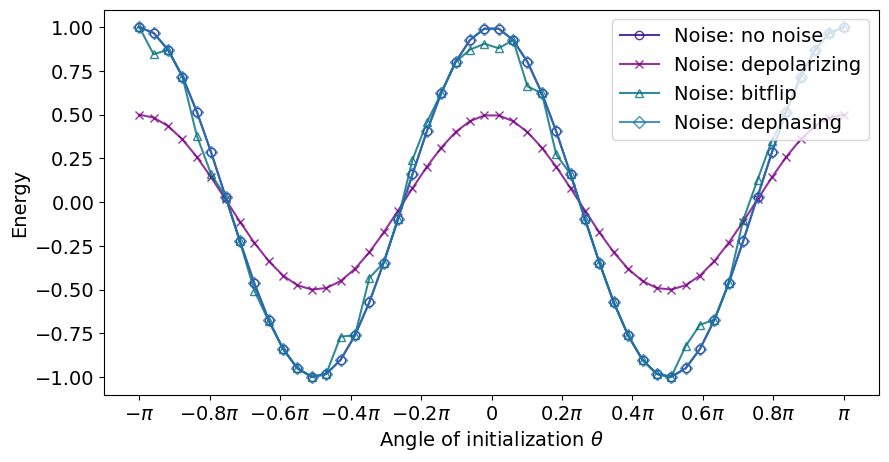

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Define the parameters
theta_list = np.linspace(-np.pi, np.pi, 50)
noise_types = ['no noise', 'depolarizing', 'bitflip', 'dephasing']  # Noise models to check

# Define custom colors and markers
color = ['#2c0084', '#7a0085', '#006f7a', 'C0']
markers = ['o', 'x', '^', 'D']

plt.figure(figsize=[10,5])

# Loop over each noise model and compute the energy
for idx, noise_type in enumerate(noise_types):
    energy_list = []
    
    # Loop over each angle for theta
    for theta in theta_list:
        # Initial system without noise
        original_system = RX(theta) @ psi0 @ RX(-theta)
        
        # Apply noise based on the selected noise model
        if noise_type == 'no noise':
            final_state = original_system
        elif noise_type == 'depolarizing':
            final_state = apply_depolarizing_noise(original_system)
        elif noise_type == 'bitflip':
            final_state = apply_bitflip_error(original_system)
        elif noise_type == 'dephasing':
            final_state = apply_dephasing_noise(original_system)

        # Compute energy for the final state
        energy = final_state[0][0] - final_state[1][1]
        energy_list.append(energy)

    # Plot the results for the current noise model with custom color and marker
    plt.plot(theta_list, energy_list, label=f'Noise: {noise_type}', color=color[idx], marker=markers[idx], markerfacecolor='none', alpha=0.8)

# Display the plot
plt.legend(loc='upper right')

plt.xlabel(r'Angle of initialization $\theta$')
plt.ylabel(r'Energy')
plt.ylim([-1.1, 1.1])

# Custom ticks and labels
ticks = np.linspace(-np.pi, np.pi, 11)
tick_labels = [
    r'$-\pi$', r'$-0.8\pi$', r'$-0.6\pi$', r'$-0.4\pi$', r'$-0.2\pi$',
    r'$0$', 
    r'$0.2\pi$', r'$0.4\pi$', r'$0.6\pi$', r'$0.8\pi$', r'$\pi$'
]
plt.xticks(ticks, tick_labels)

plt.show()


In [10]:
ket0 = np.array([1,0])

In [11]:
RX(np.pi) @ ket0

array([-1.+0.00000000e+00j,  0.-1.52695104e-16j])

In [12]:
np.round(RX(np.pi/2) @ psi0 @ RX(-np.pi/2),2 )

array([[0.+0.j, 0.+0.j],
       [0.+0.j, 1.+0.j]])

In [13]:
RX(np.pi/4) @ ket0

array([0.70710678+0.j        , 0.        -0.70710678j])

In [14]:
RX(np.pi/2) @ RZ(0.3) @ RX(-np.pi/2)

array([[0.95533649+0.29552021j, 0.        +0.j        ],
       [0.        +0.j        , 0.95533649-0.29552021j]])

In [15]:
RX(0.3)

array([[0.95533649+0.j        , 0.        -0.29552021j],
       [0.        -0.29552021j, 0.95533649+0.j        ]])

In [16]:
RX(np.pi/2) @ RZ(0.3) @ RX(-np.pi/2)

array([[0.95533649+0.29552021j, 0.        +0.j        ],
       [0.        +0.j        , 0.95533649-0.29552021j]])

In [17]:
RX(-np.pi/2)

array([[0.+0.j, 0.+1.j],
       [0.+1.j, 0.+0.j]])

In [18]:
RX(np.pi/2)

array([[0.+0.j, 0.-1.j],
       [0.-1.j, 0.+0.j]])

In [19]:
S_dagger @ H @ RZ(0.3) @ H @ S

array([[ 0.95533649+7.48626265e-18j,  0.29552021+1.09504357e-17j],
       [-0.29552021-1.09504357e-17j,  0.95533649+7.48626265e-18j]])

In [20]:
X@Z@X

array([[-1,  0],
       [ 0,  1]])

In [21]:
RX(-np.pi/2)

array([[0.+0.j, 0.+1.j],
       [0.+1.j, 0.+0.j]])